In [1]:
from langchain_ollama import ChatOllama
from dotenv import load_dotenv
from langgraph.graph import StateGraph,END,START
from model import projectplan
from langchain_tavily import TavilySearch
from typing import TypedDict
import os


In [2]:
load_dotenv()

llm=ChatOllama(
    model="gemma4:31b-cloud ",
)

planner_llm=llm.with_structured_output(projectplan)

In [3]:
def ask_llm(role: str, task: str) -> str:
    response = llm.invoke(
        f"""
You are the {role} for an AI Project Architect.

Follow these rules:
- Be practical and technically accurate.
- Clearly label assumptions.
- Do not invent user requirements.
- Prefer a simple MVP before advanced features.

TASK:
{task}
"""
    )
    return str(response.content)

In [4]:
class AgentState(TypedDict,total=False):
    idea:str
    requirements:str
    plan:dict
    error:str
    research:str
    clarification_questions:str
    architecture:str
    task_plan:str
    workflow_diagram:str
    quality_review:str
    implementation_guide:str
    
    



In [5]:
def Analyzer_Agent(state:AgentState):
    idea=state['idea'].strip()
    if not idea:
        return {"error": "Please enter a project idea."}

    analysis_prompt = f"""
You are a Senior AI Project Requirements Analyst, Software
Architect, Product Manager, and Technical Mentor.

Your job is to transform a user's initial project idea into
a clear, detailed, technically useful requirements analysis
that can be used by a Research Agent, Project Planning Agent,
and Implementation Agent.

==================================================
USER PROJECT IDEA
==================================================

{idea}

==================================================
ANALYSIS INSTRUCTIONS
==================================================

Analyze the project systematically using the following sections.

1. PROJECT OVERVIEW
- Explain the idea in simple, beginner-friendly language.
- Identify the main problem the project aims to solve.
- Explain why the problem matters.
- Describe the expected final product.
- Distinguish the user's stated goals from your assumptions.

2. PROBLEM STATEMENT
- Describe the current problem.
- Explain how users might experience this problem.
- Identify limitations of existing approaches, if known.
- Explain how the proposed project could address the problem.
- Do not claim that existing solutions are inadequate without
  evidence.

3. TARGET USERS
- Identify primary and secondary user groups.
- Describe their likely needs and workflows.
- Explain the value the project may provide to each group.
- Distinguish confirmed users from potential user groups.

4. USER STORIES AND USE CASES
Write user stories in this format:

"As a [type of user], I want [functionality],
so that [benefit]."

Include:
- Main user journey.
- Important alternative workflows.
- Expected inputs and outputs.
- Common failure scenarios.
- User interactions required for the MVP.

5. FUNCTIONAL REQUIREMENTS
List the features the application must provide.

For each feature, explain:
- Feature name.
- Purpose.
- User action or trigger.
- Input data.
- Processing or business logic.
- Expected output.
- Dependencies on other features.
- Acceptance criteria that can be tested.

Separate requirements into:
- Must-have features for the MVP.
- Should-have features for the next version.
- Optional advanced features.

6. NON-FUNCTIONAL REQUIREMENTS
Analyze relevant requirements for:
- Performance and response time.
- Reliability and error handling.
- Security and privacy.
- Scalability.
- Maintainability.
- Accessibility and usability.
- Logging and monitoring.
- Cost efficiency.

Do not invent numerical performance targets.
Mark targets requiring user confirmation as TBD.

7. AI AND AUTOMATION REQUIREMENTS
If the project uses AI, ML, LLMs, or agents, identify:
- Why AI is needed.
- Which tasks require an LLM or another model.
- Which tasks can use ordinary Python code.
- Potential tools, APIs, or external services.
- Whether structured outputs are needed.
- Whether memory or persistent storage is useful.
- Whether retrieval, embeddings, or a vector database
  are genuinely necessary.
- How outputs should be evaluated.
- Risks such as hallucinations, latency, cost, and privacy.

Do not add AI components merely to make the project appear
more advanced. If the idea does not need AI, explain why."""

    response=llm.invoke("analysis_prompt")

    return {"requirements": response.content}


In [6]:
def clarification_Agent(state:AgentState):
    result = ask_llm(
        "Requirements Clarification Specialist",
        f"""
    Project idea:
    {state['idea']}

    Initial analysis:
    {state.get('requirements', '')}

    Identify important unanswered questions.
    Prioritize questions that could significantly change
    the architecture, cost, security, or project scope.

    For each question, explain why it matters.
    If information is missing, propose a clearly labeled
    reasonable default assumption.

    Do not pretend the user has answered these questions.
    """
    )

    return {"clarification_questions": result}


In [7]:
def Research_idea(state:AgentState):
        
    if not os.getenv("TAVILY_API_KEY"):
        return {
            "research": (
                "Web research skipped: TAVILY_API_KEY is missing. "
                "Use the model's general knowledge instead."
            )
        }

    try:
        search_tool = TavilySearch(
            max_results=5,
            topic="general",
        )

        results = search_tool.invoke({
            "query": (
                "Official documentation and recommended technologies for "
                + state["idea"]
            )
        })

        return {"research": str(results)}

    except Exception as exc:
        return {"research": f"Research unavailable: {exc}"}

In [8]:
def Architecture_Agent(state:AgentState):
    result=ask_llm( 
    "Software Architect",
    f"""
    Project:
    {state['idea']}

    Requirements:
    {state.get('requirements', '')}

    Research:
    {state.get('research', '')}

    Design the system architecture.

    Explain:
    1. Frontend and backend, if needed
    2. Main components and their responsibilities
    3. Data flow between components
    4. Database and storage choices
    5. External APIs and integrations
    6. Security and error handling
    7. Why each technology is suitable

    Separate verified research from recommendations.
    Do not add unnecessary technologies.
    """
    )

    return {"architecture": result}
    

In [9]:
def plan_task(state:AgentState):
    result = ask_llm(
        "Technical Project Planner",
        f"""
    Project:
    {state['idea']}

    Architecture:
    {state.get('architecture', '')}

    Create an implementation roadmap.

    For every milestone include:
    - Goal
    - Tasks
    - Required files or modules
    - Dependencies
    - Expected deliverable
    - Acceptance criteria
    - Suggested tests

    Order tasks by dependency. Start with the smallest
    working MVP and defer optional features.
    """
    )

    return {"task_plan": result}


In [10]:
def design_workflow(state:AgentState):
    result=ask_llm(
        "Workflow Designer",
        f"""
Project:
{state['idea']}

Architecture:
{state.get('architecture', '')}

Task plan:
{state.get('task_plan', '')}

Create a Mermaid flowchart showing the system workflow.

Return valid Mermaid flowchart code beginning with:
flowchart TD

Show:
- User input
- Main processing steps
- Data storage when relevant
- External tools when relevant
- Success and failure paths

Use simple node IDs and quoted labels where necessary.
Return the diagram code only.
"""
    )

    return {"workflow_diagram": result}


In [11]:
def generate_blueprint(state:AgentState):
    prompt = f"""
Create a practical project blueprint using the provided
Pydantic schema.

PROJECT IDEA:
{state['idea']}

REQUIREMENTS:
{state.get('requirements', '')}

CLARIFICATION QUESTIONS AND ASSUMPTIONS:
{state.get('clarification_questions', '')}

RESEARCH:
{state.get('research', '')}

ARCHITECTURE:
{state.get('architecture', '')}

IMPLEMENTATION PLAN:
{state.get('task_plan', '')}

Rules:
- Produce valid structured data matching the schema.
- Start with an MVP.
- Keep component dependencies consistent.
- Do not invent facts or claim unverified research is true.
- Use technologies appropriate for the project.
"""

    result = planner_llm.invoke(prompt)
    return {"plan": result.model_dump(mode="json")}

In [12]:
def review_project(state:AgentState):
    result = ask_llm(
        "Senior Software Quality Reviewer",
        f"""
Review this proposed project.

Idea:
{state['idea']}

Blueprint:
{state.get('plan', {})}

Architecture:
{state.get('architecture', '')}

Tasks:
{state.get('task_plan', '')}

Check:
1. Missing requirements
2. Inconsistent components
3. Incorrect or missing dependencies
4. Security and privacy risks
5. Unrealistic milestones
6. Missing tests
7. Unnecessary complexity

Classify findings as Critical, Important, or Optional.
Suggest concrete fixes.

Do not claim that code has been executed or tested.
This is a design review, not runtime verification.
"""
    )

    return {"quality_review": result}

In [13]:
def guide_implement_agent(state:AgentState):
    
    prompt = f"""
Create a concise MVP project blueprint.

Project idea:
{str(state.get("idea", ""))[:250]}

Requirements summary:
{str(state.get("requirements", ""))[:500]}

Rules:
- Follow the supplied Pydantic schema exactly.
- Maximum 3 to 5 features.
- Maximum 4 components.
- Maximum 3 milestones.
- Use short descriptions.
- Avoid unnecessary technologies.
- Do not repeat the input.
"""

    result = planner_llm.invoke(prompt)
    return {"plan": result.model_dump(mode="json")}

In [14]:
graph=StateGraph(AgentState)
graph.add_node("Analyzer_Agent",Analyzer_Agent)
graph.add_node("clarification_Agent",clarification_Agent)
graph.add_node("Research_idea",Research_idea)
graph.add_node("Architecture_Agent",Architecture_Agent)
graph.add_node("plan_task",plan_task)
graph.add_node ("design_workflow",design_workflow)
graph.add_node("generate_blueprint",generate_blueprint)
graph.add_node("review_project",review_project)
graph.add_node("guide_implement_agent",guide_implement_agent)

graph.add_edge(START,"Analyzer_Agent")
graph.add_edge("Analyzer_Agent","clarification_Agent")
graph.add_edge("clarification_Agent","Research_idea")
graph.add_edge("Research_idea","Architecture_Agent")
graph.add_edge("Architecture_Agent","plan_task")
graph.add_edge("plan_task","design_workflow")
graph.add_edge("design_workflow","generate_blueprint")
graph.add_edge("generate_blueprint","review_project")
graph.add_edge("review_project","guide_implement_agent")
graph.add_edge("guide_implement_agent",END)

Workflow=graph.compile()

result = Workflow.invoke({
    "idea": "Build an AI interview preparation assistant"
})

print(result)



OutputParserException: Failed to parse ProjectPlan from completion {"project_name": "AI Interview Prep Assistant", "version": "1.0.0", "description": "A context-aware mock interview platform that allows users to upload a resume and job description, engage in a simulated interview (text/audio), and receive a detailed performance evaluation report.", "target_audience": "Job seekers, fresh graduates, and professionals preparing for role-specific interviews.", "mvp_scope": {"core_features": ["Resume and Job Description (JD) parsing for context-aware questioning.", "AI-driven mock interviewer simulating a hiring manager persona.", "Support for text and audio (Speech-to-Text) input modalities.", "Post-interview comprehensive feedback report with scoring and improvement tips."], "out_of_scope": ["Real-time video behavioral analysis (eye-tracking/emotion detection).", "Live human-in-the-loop coaching.", "Direct integration with ATS (Applicant Tracking Systems)."]}, "technical_architecture": {"

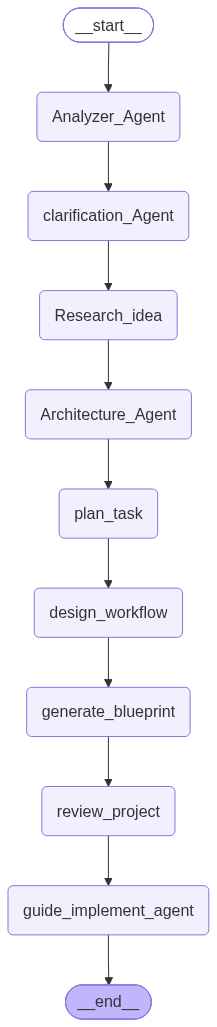

In [ ]:
Workflow

In [ ]:
if __name__ == "__main__":
    idea = input("Enter your project idea: ").strip()

    if not idea:
        raise SystemExit("Please enter a valid project idea.")

    try:
        result = graph.invoke({"idea": idea})

        print("\n========== PROJECT BLUEPRINT ==========")
        print(result.get("plan", {}))

        print("\n========== ARCHITECTURE ==========")
        print(result.get("architecture", ""))

        print("\n========== IMPLEMENTATION ROADMAP ==========")
        print(result.get("task_plan", ""))

        print("\n========== WORKFLOW DIAGRAM ==========")
        print(result.get("workflow_diagram", ""))

        print("\n========== QUALITY REVIEW ==========")
        print(result.get("quality_review", ""))

        print("\n========== IMPLEMENTATION GUIDE ==========")
        print(result.get("implementation_guide", ""))

        print("\n========== CLARIFICATION QUESTIONS ==========")
        print(result.get("clarification_questions", ""))

    except Exception as exc:
        print(f"Project workflow failed: {exc}")

Project workflow failed: 'StateGraph' object has no attribute 'invoke'
